# Proximal Policy Optimization on CartPole

**Family:** Reinforcement learning | **Level:** Advanced | **Dataset:** `CartPole-v1` | **Runs on:** CPU, about 2 minute(s)

Take several safe gradient steps per batch by clipping the policy ratio.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- The clipped surrogate objective
- Generalised advantage estimation
- Why several epochs per batch are safe with clipping
- How to log the clip fraction

**Prerequisites:**

- Probability basics
- Markov decision processes

**Skills you will have afterwards:**

- Run several seeds
- Report learning curves with spread
- Compare with a baseline policy

## 2. Real-World Problem

**Context.** Large policy updates can destroy performance.

**The problem.** Balance CartPole with a stable policy gradient method.

**Why it matters.** PPO is the most used on policy deep RL algorithm.

**Why machine learning.** The policy and value networks are trained on batches.

**Why this algorithm.** PPO is the practical default for many tasks.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### Proximal Policy Optimization Algorithms

- **Type:** foundational paper
- **Authors:** Schulman, J., Wolski, F., Dhariwal, P., Radford, A. and Klimov, O.
- **Year and venue:** 2017, arXiv:1707.06347
- **DOI or URL:** https://arxiv.org/abs/1707.06347
- **Verification:** arXiv abstract page 2026-11-17
- **Research objective:** Stable policy gradient with simple updates.
- **Methodology:** Clipped surrogate objective with several epochs on each batch.
- **Dataset:** MuJoCo continuous control and Atari.
- **Main findings:** Competitive sample efficiency with a simpler implementation than trust region methods.
- **Limitations:** Sensitive to implementation details.

### Deep Reinforcement Learning that Matters

- **Type:** benchmark paper
- **Authors:** Henderson, P. et al.
- **Year and venue:** 2018, AAAI 2018; arXiv:1709.06560
- **DOI or URL:** https://arxiv.org/abs/1709.06560
- **Verification:** arXiv abstract page 2026-11-17
- **Research objective:** Study reproducibility in deep RL.
- **Methodology:** Compare algorithms across seeds, codebases and hyperparameters.
- **Dataset:** MuJoCo tasks.
- **Main findings:** Results change strongly with seeds and implementation, so several seeds are needed.
- **Limitations:** Limited set of tasks.

### Deep Reinforcement Learning at the Edge of the Statistical Precipice

- **Type:** benchmark paper
- **Authors:** Agarwal, R., Schwarzer, M., Castro, P. S., Courville, A. and Bellemare, M. G.
- **Year and venue:** 2021, NeurIPS 2021; arXiv:2108.13264
- **DOI or URL:** https://arxiv.org/abs/2108.13264
- **Verification:** arXiv abstract page 2026-11-17
- **Research objective:** Report RL results with uncertainty.
- **Methodology:** Interquartile mean, stratified bootstrap intervals, performance profiles.
- **Dataset:** Atari and other benchmarks.
- **Main findings:** Few seed point estimates mislead.
- **Limitations:** Needs enough runs to be useful.

**Relationship to this notebook.** Schulman et al. introduce PPO. Our version is minimal: one environment, no observation normalisation, no learning rate schedule. It is not a reproduction of their experiments. Agarwal et al. argue that few runs can mislead, and we use three seeds only. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**Ratio.** $r_t(\theta) = \pi_\theta(a_t|s_t)/\pi_{\theta_{old}}(a_t|s_t)$.

**Clipped objective.** $L^{CLIP} = \mathbb{E}\big[\min\big(r_t \hat A_t,\ \text{clip}(r_t, 1-\epsilon, 1+\epsilon)\hat A_t\big)\big]$ with $\epsilon = 0.2$.

**GAE.** $\hat A_t = \sum_{l\ge 0}(\gamma\lambda)^l \delta_{t+l}$, $\delta_t = r_t + \gamma V(s_{t+1}) - V(s_t)$.

**Total loss.** $-L^{CLIP} + c_v (V - \hat R)^2 - c_e H(\pi)$.

**Limits.** Many implementation details matter, sensitive to the learning rate.

## 5. Dataset Introduction

**CartPole-v1** (Gymnasium, `classic_control`). A pole is hinged to a cart. State: cart position, cart velocity, pole angle, pole angular velocity (4 real numbers). Actions: push left or right. Reward +1 per step. An episode ends when the pole falls past about 12 degrees, the cart leaves the track, or after 500 steps. The maximum return is 500, and a mean of 475 is the usual solved threshold. There is no dataset, the environment is simulated.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
from IPython.display import display

from ml_lab.rl import tabular, deep
from ml_lab.evaluation import evaluate_policy
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "ppo"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()
print("gymnasium", gym.__version__)

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0
gymnasium 1.4.0


## 6. Exploratory Data Analysis

There is no dataset. We inspect the environment: observation and action spaces, rewards and a random policy baseline. 

In [2]:
env = gym.make("CartPole-v1")
print("observation space:", env.observation_space)
print("action space:", env.action_space, "| max episode steps:", env.spec.max_episode_steps)
rng0 = np.random.default_rng(0)
random_returns = evaluate_policy(lambda: gym.make("CartPole-v1"), lambda s: int(rng0.integers(2)), episodes=50, seed=0)
print("random policy over 50 episodes:", {k: round(v, 1) for k, v in random_returns.items()})

observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
action space: Discrete(2) | max episode steps: 500
random policy over 50 episodes: {'mean_return': 25.1, 'median_return': 20.0, 'std_return': 13.6, 'mean_length': 25.1}


## 7. Data Preprocessing

No preprocessing: the 4 state values are fed directly to a network with two hidden layers of 64 units. Training uses seeds 0, 1 and 2. Evaluation uses 20 fresh episodes per seed with environment seeds from 1000, never seen in training. Only a CPU is used, so the budgets are small and results will be below long GPU runs.

In [3]:
TOTAL_STEPS = 60000
SEEDS = [0, 1, 2]
make_env = lambda: gym.make("CartPole-v1")
GRID = np.linspace(1000, TOTAL_STEPS, 40)

## 8. Algorithm Implementation

### 8.1 Concept

Collect a batch with the current policy, then improve it for a few epochs, but stop pushing in directions where the new policy already differs a lot from the old one.

### 8.2 Python implementation from scratch

Source of the training function (`ml_lab.rl.deep.train_ppo`). Truncation at the time limit is treated like a terminal state, which adds a small bias.

In [4]:
print(inspect.getsource(deep.train_ppo))

def train_ppo(env_id="CartPole-v1", seed=0, total_steps=60000, rollout=1024, epochs=10, minibatch=128, lr=1e-3,
              gamma=0.99, lam=0.95, clip=0.2, vf_coef=0.5, ent_coef=0.0, hidden=64):
    """PPO with clipped objective and GAE. Truncation is treated as episode end (small bias)."""
    seed_everything(seed)
    rng = np.random.default_rng(seed)
    env = gym.make(env_id)
    obs_dim, n_actions = env.observation_space.shape[0], env.action_space.n
    actor, critic = mlp(obs_dim, n_actions, hidden), mlp(obs_dim, 1, hidden)
    opt = torch.optim.Adam(list(actor.parameters()) + list(critic.parameters()), lr=lr)
    obs, _ = env.reset(seed=seed)
    returns, steps, total, t = [], [], 0.0, 0
    clip_log = []
    while t < total_steps:
        O, A, LP, R, D, V = [], [], [], [], [], []
        for _ in range(rollout):
            with torch.no_grad():
                dist = categorical(actor, obs)
                action = dist.sample()
                value = critic(to_tensor(obs)

### 8.3 Library implementation

The algorithm is implemented in `src/ml_lab/rl` without an RL library. Gymnasium supplies only the environment.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `rollout` | Steps per batch. |
| `epochs`, `minibatch` | Optimisation passes and minibatch size. |
| `clip` | Ratio clip range. |
| `lam` | GAE parameter. |
| `ent_coef` | Entropy bonus. |

## 9. Model Training

Three seeds, 60 000 steps, rollouts of 1024 steps, 10 epochs, minibatch 128, learning rate 1e-3.

In [5]:
runs = {}
for seed in SEEDS:
    runs[seed] = deep.train_ppo(seed=seed, total_steps=TOTAL_STEPS)
    last = runs[seed]["returns"][-10:]
    print("seed", seed, "| episodes", len(runs[seed]["returns"]), "| mean training return of last 10 episodes:", round(float(np.mean(last)), 1))

seed 0 | episodes 253 | mean training return of last 10 episodes: 500.0


seed 1 | episodes 254 | mean training return of last 10 episodes: 500.0


seed 2 | episodes 263 | mean training return of last 10 episodes: 474.5


## 10. Evaluation

Greedy policy on 20 fresh episodes per seed. Floor: random policy.

In [6]:
rng_eval = np.random.default_rng(0)
random_eval = evaluate_policy(make_env, lambda s: int(rng_eval.integers(2)), episodes=20, seed=1000)
evals = {seed: evaluate_policy(make_env, runs[seed]["policy"], episodes=20, seed=1000, success_threshold=475) for seed in SEEDS}
table = pd.DataFrame(evals).T[["mean_return", "std_return", "success_rate"]]
display(table.round(1))
means = np.array([e["mean_return"] for e in evals.values()])
METRICS = {"eval_mean_return": float(means.mean()), "eval_std_across_seeds": float(means.std(ddof=1)), "eval_min_seed": float(means.min()), "eval_max_seed": float(means.max()),
           "random_policy_mean_return": float(random_eval["mean_return"]), "share_of_seeds_solved": float((means >= 475).mean())}
EXTRA = {"per_seed_eval_return": [float(m) for m in means], "training_steps_per_seed": [int(runs[s]["steps"][-1]) for s in SEEDS]}
CONFIG = {"total_steps": TOTAL_STEPS, "rollout": 1024, "epochs": 10, "minibatch": 128, "lr": 1e-3, "clip": 0.2, "gamma": 0.99, "lambda": 0.95, "seeds": 3}

record = ExperimentRecord(notebook=NOTEBOOK_ID, family="reinforcement_learning", algorithm="PPO", dataset="CartPole-v1",
                          task="control", seed=SEED, config=CONFIG, metrics=METRICS, extra=EXTRA)
print("saved:", record.save())
display(pd.Series(METRICS, name="metric").round(4).to_frame())

,mean_return,std_return,success_rate
0,500.0,0.0,1.0
1,498.5,6.5,1.0
2,500.0,0.0,1.0


saved: experiments/results/ppo.json


,metric
eval_mean_return,499.500
eval_std_across_seeds,0.866
eval_min_seed,498.500
eval_max_seed,500.000
random_policy_mean_return,21.700
share_of_seeds_solved,1.000


## 11. Visualization

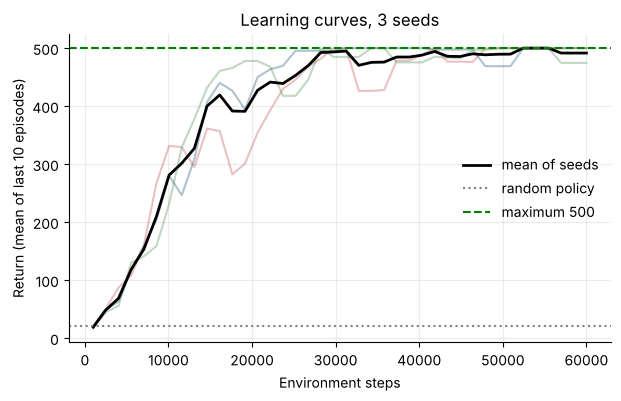

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
curves = np.array([deep.curve_on_grid(runs[s]["steps"], runs[s]["returns"], GRID, window=10) for s in SEEDS])
for c in curves:
    ax.plot(GRID, c, alpha=0.35)
ax.plot(GRID, np.nanmean(curves, axis=0), color="black", linewidth=2, label="mean of seeds")
ax.axhline(random_eval["mean_return"], color="gray", linestyle=":", label="random policy"); ax.axhline(500, color="green", linestyle="--", label="maximum 500")
ax.set_xlabel("Environment steps"); ax.set_ylabel("Return (mean of last 10 episodes)"); ax.set_title("Learning curves, 3 seeds"); ax.legend()
save_figure(fig, NOTEBOOK_ID, "curves"); plt.show()

## 12. Interpretation

The clip fraction shows how often the ratio left the trust region.

In [8]:
print("per seed evaluation return:", np.round(means, 1))
print("a seed counts as solved when its evaluation mean is at least 475; solved seeds:", int((means >= 475).sum()), "of", len(SEEDS))
final_train = np.array([np.mean(runs[s]["returns"][-10:]) for s in SEEDS])
print("training return of last 10 episodes versus evaluation return:", np.round(final_train, 1), "vs", np.round(means, 1))
clip = np.array([[c for _, c in runs[s]["clip_log"]] for s in SEEDS])
print("mean clip fraction per rollout, by seed:", np.round(clip.mean(axis=1), 3))

per seed evaluation return: [500.  498.5 500. ]
a seed counts as solved when its evaluation mean is at least 475; solved seeds: 3 of 3
training return of last 10 episodes versus evaluation return: [500.  500.  474.5] vs [500.  498.5 500. ]
mean clip fraction per rollout, by seed: [0.058 0.062 0.075]


## 13. Experiments and Challenges

### Experiment 1: Clip range

0.05, 0.2 and 0.5. Two seeds and about 30 000 steps.

In [9]:
for name, kw in [("0.05", dict(clip=0.05)), ("0.2", dict(clip=0.2)), ("0.5", dict(clip=0.5))]:
    rets = []
    for seed in [0, 1]:
        out = deep.train_ppo(seed=seed, total_steps=30720, **kw)
        ev = evaluate_policy(make_env, out["policy"], episodes=10, seed=1000)
        rets.append(ev["mean_return"])
    print(f"{name}: evaluation return by seed {np.round(rets, 1)}, mean {np.mean(rets):.1f}")

0.05: evaluation return by seed [500. 500.], mean 500.0


0.2: evaluation return by seed [500.  390.3], mean 445.1


0.5: evaluation return by seed [496.5 498.1], mean 497.3


### Experiment 2: Epochs per batch

1, 4 and 10. Two seeds and about 30 000 steps.

In [10]:
for name, kw in [("1", dict(epochs=1)), ("4", dict(epochs=4)), ("10", dict(epochs=10))]:
    rets = []
    for seed in [0, 1]:
        out = deep.train_ppo(seed=seed, total_steps=30720, **kw)
        ev = evaluate_policy(make_env, out["policy"], episodes=10, seed=1000)
        rets.append(ev["mean_return"])
    print(f"{name}: evaluation return by seed {np.round(rets, 1)}, mean {np.mean(rets):.1f}")

1: evaluation return by seed [327.  370.8], mean 348.9


4: evaluation return by seed [500. 500.], mean 500.0


10: evaluation return by seed [500.  390.3], mean 445.1


### Experiment 3: GAE lambda

0.0 (one step TD) versus 0.95. Two seeds and about 30 000 steps.

In [11]:
for name, kw in [("lambda 0.0", dict(lam=0.0)), ("lambda 0.95", dict(lam=0.95))]:
    rets = []
    for seed in [0, 1]:
        out = deep.train_ppo(seed=seed, total_steps=30720, **kw)
        ev = evaluate_policy(make_env, out["policy"], episodes=10, seed=1000)
        rets.append(ev["mean_return"])
    print(f"{name}: evaluation return by seed {np.round(rets, 1)}, mean {np.mean(rets):.1f}")

lambda 0.0: evaluation return by seed [ 18.  223.1], mean 120.5


lambda 0.95: evaluation return by seed [500.  390.3], mean 445.1


### Exercises for learners

1. Repeat with a different set of seeds and report the spread.
2. Change the discount factor and describe what happens to the learned behaviour.
3. Change one hyperparameter by a factor of 10 and compare learning curves.

## 14. Research Discussion

Schulman et al. report PPO as stable and simple. Our small test cannot confirm their comparison with other methods, but the curves of three seeds show how stable the minimal version is on CartPole. Agarwal et al. recommend interval estimates, which need more seeds than we use.

**Dataset and method differences.** The papers above use other data and protocols. We do not claim that our numbers agree or disagree with them. This notebook only shows whether the behaviour they describe appears on our data.

**Possible improvements.** Observation normalisation, learning rate decay, several parallel environments, and at least 10 seeds with intervals.

**Research limitations.** One dataset and one seed for the headline numbers. Three seeds and a CPU sized step budget, so these runs show trends, not converged scores.

## 15. Summary and Further Reading

**Key takeaways**

- Clipping limits the policy change.
- GAE trades bias for variance.
- Details and seeds matter.

**Use cases.** General on policy deep RL.

**Limitations.** Implementation details matter.

**Recommended next notebook.** Fundamentals.

**Further reading.** See `references.md` in this folder.